# Deplano et al. (2026): stationary entanglement of a levitated oscillator with an optical field

Q. Deplano, A. Pontin, F. Marino and F. Marin,
*Stationary entanglement of a levitated oscillator with an optical field*,
Science **394**, 113 (2026), [doi:10.1126/science.aeh1375](https://doi.org/10.1126/science.aeh1375)
(open version used here: arXiv:2602.03456v2, 19 March 2026, which contains the main text and the
supplementary materials; section and equation numbers S1, S2, ... refer to its supplement).

A 100 nm silica sphere in a tweezer made of two lasers (A and B, 1064 nm, power ratio 3:1) sits near
a node of a cavity ($\kappa/2\pi$ = 58 kHz). Field A drives one longitudinal cavity mode on its red
sideband (cooling, and a meter of the motion), field B drives a mode two free spectral ranges away on
its blue sideband (two-mode squeezing), both through coherent scattering. The paper shows that the
transverse "bright" mode $x_b$ (motion along the projection of the cavity axis) is entangled with a
**propagating** mode of the B output field, defined by a flat spectral window of width $\Gamma_\xi$
centred on the Stokes sideband. The witness is the smallest symplectic eigenvalue $\nu_-$ of the
partially transposed covariance matrix of $(Q_\xi, P_\xi, x_b, p_b)$, with vacuum $= 1$ and
entanglement for $\nu_- < 1$; the paper quotes $E_N = -\log_2 \nu_-$.

This notebook builds the paper's two-cavity-mode model with levisim (one toy `MultiTrap` per cavity
mode, joined by `levisim.multiphysics.output_modes.stack_cavity_modes`), computes the joint
covariance of the filtered output mode and the intracavity motion
(`output_modes.output_mode_covariance`), and compares with

1. the coupling rates of the Fig. 2 caption and the worked covariance matrix of Eq. (S45),
2. the axial ($z$) mode contribution (Eqs. S52, S54) and the intracavity matrix of Sec. IV A,
3. $\nu_-$ against the mode width $\Gamma_\xi$ (Fig. 3),
4. the measured covariance matrices of Figs. S13-S14 and $\nu_-$ against detuning (Fig. 4), using the
   ten fitted parameter sets of Fig. S6.

Runtime: about 10 s of computation after the imports.

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| cavity linewidth $\kappa/2\pi$ | 58 ± 0.6 kHz (systematic ±1 kHz) | main text; Sec. V |
| detection efficiency $\eta$ | 0.283 ± 0.006 (systematic ±0.025) | main text; Sec. V |
| per-dataset $(\Omega_x, \Omega_y, g_x, g_y, \Gamma_x, \Gamma_y, \mathcal{P})$ | ten sets, digitised | Fig. S6 (with $\langle\Omega_x\rangle$, $\langle\Omega_y\rangle$ = 110.32, 98.16 kHz from Sec. III C) |
| the Fig. 2 / Fig. S5 dataset | (110.51, 98.29, 9.01, 7.50, 3.00, 2.67) kHz, $\mathcal{P}$ = 0.292 | Fig. S5 caption |
| Eq. (S45) example | (110.5, 98.3, 9.0, 7.5, 3.0, 2.7, $\Delta_A$ = −98.6, $\Delta_B$ = 96.6) kHz, $\mathcal{P}$ = 0.291 | Sec. II D |
| B couplings | $g_{B,j} = \sqrt{\mathcal{P}}\, g_j$ ($\mathcal{P}$ = B/A power ratio) | Sec. II A |
| detunings and $\Gamma_\xi$ of the ten datasets | $(\Delta_A, \Delta_B, \Gamma_\xi)$, e.g. (−109.16, 106.04, 30) kHz | Figs. S13-S14 (raster images, read by eye) |
| axial mode $(\Omega_z, \Gamma_z, g_{A,z}, g_{B,z})/2\pi$ | (19.25, 32.6, 2.25, 1.22) kHz | Sec. III C 1, Fig. S9 |
| intracavity example | (110.5, 98.4, 8.9, 7.7, 2.3, 2.0, −137.8, 137.4) kHz, $\mathcal{P}$ = 0.292, tilt $\varphi$ = 2.0° | Sec. IV A |

Conventions and modelling choices:

- **Signs.** The paper's detuning $\Delta = 2\pi(\nu_L - \nu_c)$ and its cavity susceptibility
  $\chi_\alpha(\omega) = [\kappa/2 - i(\Delta_\alpha + \omega)]^{-1}$ (Eq. S21) are levisim's (red is
  $\Delta < 0$, unlike the other paper notebooks). Its Langevin equations (S1-S4) are levisim's
  linearised equations with a real coupling $G = g$: $\dot P_\alpha \ni 2g\,x$, $\dot p \ni 2g\,Q_\alpha$. So
  the paper's $g$ is levisim's toy `gjn_dict` value, with no factor.
- **Heating.** The paper's $\Gamma_j$ are phonon heating rates ($\dot{\langle n\rangle} = \Gamma_j$; momentum
  diffusion $4\Gamma_j$ in Eq. S5, no damping). levisim's bath damps and drives both quadratures; a bath
  at 300 K with damping $\Gamma_j / n_\mathrm{th}$ ($\approx 3 \times 10^{-4}$ s⁻¹) gives the same heating
  rate. The two differ by $\langle x_b p_b\rangle \approx -D/2\Omega_b \approx -0.03$ and change $\nu_-$ by
  at most $10^{-3}$ (shown below). The fitted rates already contain recoil, so the MultiTraps are built
  with `photon_recoil=False`.
- **Two cavity modes.** A `MultiTrap` has one cavity mode, so one is built per laser (same
  mechanics, its own $\Delta$ and couplings) and the two are joined by `stack_cavity_modes`. The modes
  are two FSR apart, so they interact only through the motion.
- **Axial mode.** In the paper $z$ couples through a small tilt of the cavity axis out of the tweezer
  transverse plane, i.e. through the same quadrature as $x$ and $y$ (real $2g_{\alpha,z}$ in Eq. S5).
  A levisim `z` dimension couples with the node coherent-scattering phase $G = i g_z$ instead, so $z$ is
  added with `output_modes.add_mechanical_mode`, which couples like $x$, $y$.
- **The propagating mode.** $a_\xi = \int \xi(\omega) a_\mathrm{out}(\omega)\, d\omega/2\pi$ with a flat
  $\xi = \sqrt{2\pi/\Gamma_\xi}$ on $|\omega + \Omega_b| < \Gamma_\xi/2$ (`rectangular_filter`), and
  $a_\mathrm{out} = \sqrt\eta(\sqrt\kappa\, a_B - a_\mathrm{in}) + \sqrt{1-\eta}\, a_v$ (Eqs. S23, S28).

In [ ]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # paper_tools.py sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment, minimize_scalar

from levisim.core.constants import kB, ħ
from levisim.core.units import kHz, Hz
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.core.logger import set_console_level
from levisim.multiphysics.multitrap import MultiTrap
from levisim.multiphysics.output_modes import (
    stack_cavity_modes, add_mechanical_mode, rectangular_filter, output_mode_covariance, rectangular_filter_scan,
)
from levisim.analysis.gaussian_states import partially_transposed_symplectic_eigenvalues, is_physical

from paper_tools import load_digitised

set_plt_rcParams_to_xmgrace_style()
plt.rcParams['figure.dpi'] = 80
DATA = load_digitised('deplano2026_figs3_4_S6_S13_S14.json')
T_START = time.time()

## The model in levisim

`cavity_mode` builds one cavity mode with the particle's transverse modes; `deplano_system` joins
the A and B modes and, optionally, adds the axial mode. `bright_frame` is the change of variables of
Eqs. (S6-S10): $x_b = (g_x x + g_y y)/g_b$, with $\tan\theta = \sqrt{\Omega_x/\Omega_y}\, g_x/g_y$,
$\Omega_b^2 = \Omega_x^2 \sin^2\theta + \Omega_y^2\cos^2\theta$ and $g_b^2 = (g_x^2\Omega_x + g_y^2\Omega_y)/\Omega_b$.

In [ ]:
κ, η = 58*kHz, 0.283
Z = dict(Ω=19.25*kHz, Γ=32.6*kHz, gA=2.25*kHz, gB=1.22*kHz)    # Sec. III C 1


def cavity_mode(Ω, g, heating, Δ, κ=κ):
    """One cavity mode and the transverse modes; heating = phonon heating rates, via a 300 K bath"""
    n_th = {label: 1/np.expm1(ħ*Ω[label]/(kB*300.0)) for label in Ω}
    toy_params = dict(Ω_model='custom', toy_Ωjn_dict=dict(Ω), gjn_dict=dict(g), use_Γ_formula=False,
                      Γjn_dict={label: heating[label]/n_th[label] for label in Ω}, T=300.0)
    return MultiTrap(num_traps=1, Cartesian_axes_per_trap=2, toy_params=toy_params,
                     cavity_kwargs=dict(κ=κ, Δ=Δ), photon_recoil=False)


def deplano_system(p, z=None, κ=κ):
    """p = dict(Ωx, Ωy, gx, gy, Γx, Γy, ΔA, ΔB, P) in kHz (P dimensionless)"""
    Ω = dict(x1=p['Ωx']*kHz, y1=p['Ωy']*kHz)
    heating = dict(x1=p['Γx']*kHz, y1=p['Γy']*kHz)
    gA = dict(x1=p['gx']*kHz, y1=p['gy']*kHz)
    gB = {label: np.sqrt(p['P'])*g for label, g in gA.items()}
    system = stack_cavity_modes([cavity_mode(Ω, gA, heating, p['ΔA']*kHz, κ),
                                 cavity_mode(Ω, gB, heating, p['ΔB']*kHz, κ)], ['A', 'B'])
    if z is not None:
        system = add_mechanical_mode(system, 'z1', z['Ω'], {'A': z['gA'], 'B': z['gB']}, heating=z['Γ'], damping=1e-2)
    return system


def bright_frame(p):
    """θ, Ω_b, g_b [kHz] and the map (Q, P, x, p_x, y, p_y) → (Q, P, x_b, p_b) of Eq. (S6)"""
    Ωx, Ωy = p['Ωx'], p['Ωy']
    θ = np.arctan(np.sqrt(Ωx/Ωy) * p['gx']/p['gy'])
    Ωb = np.sqrt(Ωx**2*np.sin(θ)**2 + Ωy**2*np.cos(θ)**2)
    gb = np.sqrt((p['gx']**2*Ωx + p['gy']**2*Ωy)/Ωb)
    T = np.zeros((4, 6))
    T[0, 0] = T[1, 1] = 1
    T[2, 2], T[2, 4] = np.sqrt(Ωb/Ωx)*np.sin(θ), np.sqrt(Ωb/Ωy)*np.cos(θ)
    T[3, 3], T[3, 5] = np.sqrt(Ωx/Ωb)*np.sin(θ), np.sqrt(Ωy/Ωb)*np.cos(θ)
    return θ, Ωb, gb, T


def ν_minus(V):
    return partially_transposed_symplectic_eigenvalues(V, (0,)).min()


def V_propagating(system, p, widths, η=η):
    """V of (Q_ξ, P_ξ, x_b, p_b) for flat windows of the given widths [kHz] centred at -Ω_b"""
    _, Ωb, _, T = bright_frame(p)
    Vs = rectangular_filter_scan(system, 'B', -Ωb*kHz, np.atleast_1d(widths)*kHz, η=η, modes=['x1', 'y1'])
    return np.array([T @ V @ T.T for V in Vs])


S45 = dict(Ωx=110.5, Ωy=98.3, gx=9.0, gy=7.5, Γx=3.0, Γy=2.7, ΔA=-98.6, ΔB=96.6, P=0.291)
θ, Ωb, gb, _ = bright_frame(S45)
print(f'bright mode: θ = {np.degrees(θ):.1f}°, Ω_b/2π = {Ωb:.2f} kHz, g_A/2π = g_b/2π = {gb:.2f} kHz,'
      f' g_B/2π = √P·g_b/2π = {np.sqrt(S45["P"])*gb:.2f} kHz   (Fig. 2 caption: 106 ± 0.1, 11.7 ± 0.2, 6.3 ± 0.1 kHz)')

bright mode: θ = 51.8°, Ω_b/2π = 106.01 kHz, g_A/2π = g_b/2π = 11.69 kHz, g_B/2π = √P·g_b/2π = 6.30 kHz   (Fig. 2 caption: 106 ± 0.1, 11.7 ± 0.2, 6.3 ± 0.1 kHz)


### Stability

Field B alone (blue detuned, $g_B$ comparable to $\kappa$) anti-damps the motion, so the B-mode
`MultiTrap` on its own is linearly unstable and levisim logs a WARNING when it is built (below). The
physical system is the joint one, where field A's cooling wins; its drift matrix is stable for every
parameter set used here. The slowest mode of the 3D system is the weakly cooled axial mode.

In [ ]:
system_2d = deplano_system(S45)            # logs the expected WARNING for the B-only MultiTrap
system_3d = deplano_system(S45, z=Z)
set_console_level('ERROR')                  # the same warning would repeat for every system built below
for name, system in (('A + B + (x, y)', system_2d), ('A + B + (x, y, z)', system_3d)):
    λ = np.linalg.eigvals(system.A)
    print(f'{name:18s}: max Re λ = {λ.real.max():9.1f} /s  (slowest decay time {-1e3/λ.real.max():.1f} ms)')

A + B + (x, y)    : max Re λ =   -9439.5 /s  (slowest decay time 0.1 ms)
A + B + (x, y, z) : max Re λ =     -49.4 /s  (slowest decay time 20.2 ms)


2026-11-19 20:40:40.162 | WARNING  | levisim.multiphysics.multitrap:_check_linear_stability:527 - MultiTrap(1×2): 4 of the 6 drift-matrix eigenvalues have a positive real part (largest Re λ = +3946 /s, an e-folding time of 0.253 ms, on the mode at |Im λ| = 110.29 kHz), so the linearised dynamics are unstable and have no steady state: the stationary spectra are formally finite but do not describe a physical steady state. Check the detuning Δ, the couplings and the tweezer phases φn.
2026-11-19 20:40:40.163 | WARNING  | levisim.multiphysics.multitrap:_check_linear_stability:527 - MultiTrap(1×2): 4 of the 6 drift-matrix eigenvalues have a positive real part (largest Re λ = +3946 /s, an e-folding time of 0.253 ms, on the mode at |Im λ| = 110.29 kHz), so the linearised dynamics are unstable and have no steady state: the stationary spectra are formally finite but do not describe a physical steady state. Check the detuning Δ, the couplings and the tweezer phases φn.


## The worked example of Eq. (S45)

Sec. II D prints $V^{\xi B}$ for one parameter set without its $\Gamma_\xi$. levisim reproduces it at
$\Gamma_\xi/2\pi$ = 40 kHz, the optimum named in Sec. IV. Shown for levisim's own bath and for the
paper's momentum-only diffusion (the bath replaced in the drift and noise matrices).

In [ ]:
def with_momentum_diffusion(system, heating):
    """The paper's mechanical noise (Eq. S5): no damping, diffusion 4Γ on the momentum only"""
    A, B, N = system.A.copy(), system.B.copy(), system.N.copy()
    for label, Γ in heating.items():
        iX, iP = system.quadrature_indices(label)
        A[iX, iX] = A[iP, iP] = 0.0
        B[iX, iX], B[iP, iP] = 0.0, np.sqrt(4*Γ)
        N[iX, iX] = N[iP, iP] = 1.0
    return type(system)(A, B, N, list(system.labels), dict(system.cavities))


V_S45_paper = np.array(DATA['eqS45']['V'])
system_2d_paper = with_momentum_diffusion(system_2d, dict(x1=3.0*kHz, y1=2.7*kHz))
np.set_printoptions(precision=3, suppress=True)
for name, system in (('levisim bath', system_2d), ('momentum diffusion (paper)', system_2d_paper)):
    V = V_propagating(system, S45, 40)[0]
    print(f'{name}: ν- = {ν_minus(V):.4f}, max |V - V(S45)| = {np.abs(V - V_S45_paper).max():.3f}')
    print(V)
print('Eq. (S45):'); print(V_S45_paper, f' ν- = {ν_minus(V_S45_paper):.4f}')

widths = np.arange(10, 50.01, 0.5)
ν_bath = [ν_minus(V) for V in V_propagating(system_2d, S45, widths)]
ν_diff = [ν_minus(V) for V in V_propagating(system_2d_paper, S45, widths)]
print(f'largest difference in ν- between the two bath models, Γξ = 10-50 kHz: {np.max(np.abs(np.subtract(ν_bath, ν_diff))):.1e}')

levisim bath: ν- = 0.8830, max |V - V(S45)| = 0.027
[[ 1.496  0.     0.354  1.29 ]
 [ 0.     1.496  1.311 -0.367]
 [ 0.354  1.311  3.891 -0.027]
 [ 1.29  -0.367 -0.027  3.816]]
momentum diffusion (paper): ν- = 0.8831, max |V - V(S45)| = 0.004
[[ 1.496  0.     0.351  1.292]
 [ 0.     1.496  1.312 -0.358]
 [ 0.351  1.312  3.891  0.   ]
 [ 1.292 -0.358  0.     3.814]]
Eq. (S45):
[[ 1.5   0.    0.35  1.29]
 [ 0.    1.5   1.31 -0.36]
 [ 0.35  1.31  3.89  0.  ]
 [ 1.29 -0.36  0.    3.81]]  ν- = 0.8870
largest difference in ν- between the two bath models, Γξ = 10-50 kHz: 1.1e-03


## The axial mode

The supplement treats $z$ perturbatively: Eq. (S52) for its optical damping and Eq. (S54) for its
contribution, through the cavity fields, to $\langle x_b^2\rangle$ (and $\langle p_b^2\rangle =
(\Omega_z/\Omega_b)^2\langle x_b^2\rangle$), which is added to $V_{33}$, $V_{44}$ before computing $\nu_-$.
levisim's 3D system gives the same contribution exactly, and confirms that the filter removes $z$
from the optical block.

In [ ]:
def eq_S52_S54(p, z=Z, κ=κ):
    """γ_opt and the z contributions to 〈x_b²〉, 〈p_b²〉 from the supplement's Eqs. (S52, S54), all in 2π·Hz"""
    Ωx, Ωy, gx, gy = (p[k]*kHz for k in ('Ωx', 'Ωy', 'gx', 'gy'))
    ΔA, ΔB, P = p['ΔA']*kHz, p['ΔB']*kHz, p['P']
    _, Ωb, gb, _ = bright_frame(p)
    Ωb, gb = Ωb*kHz, gb*kHz
    χc = lambda ω, Δ: 1/(κ/2 - 1j*(Δ + ω))
    χm = lambda ω, Ω: Ω/(Ω**2 - ω**2)
    w = z['Ω']
    γ_opt = 2*z['gA']**2*np.real(χc(w, ΔA) - χc(-w, ΔA)) + 2*z['gB']**2*np.real(χc(w, ΔB) - χc(-w, ΔB))
    S = gx**2*χm(w, Ωx) + gy**2*χm(w, Ωy)
    χ_eff = S/gb**2 / (1 - 2j*S*(χc(w, ΔA) - np.conj(χc(-w, ΔA)) + P*χc(w, ΔB) - P*np.conj(χc(-w, ΔB))))
    term = (χc(w, ΔA) - np.conj(χc(-w, ΔA)))*z['gA'] + (χc(w, ΔB) - np.conj(χc(-w, ΔB)))*np.sqrt(P)*z['gB']
    xx = 8*gb**2*abs(χ_eff)**2*abs(term)**2*z['Γ']/γ_opt
    return γ_opt, xx, (w/Ωb)**2*xx


γ_opt, xx_S54, pp_S54 = eq_S52_S54(S45)
V2, V3 = V_propagating(system_2d, S45, 40)[0], V_propagating(system_3d, S45, 40)[0]
print(f'Eq. (S52): γ_opt/2π = {γ_opt/Hz:.1f} Hz  (Fig. S9 caption: "14.5", unit not printed)')
print(f'z contribution to 〈x_b²〉: Eq. (S54) {xx_S54:.3f}, levisim 3D {V3[2, 2] - V2[2, 2]:.3f}   (text: 0.22)')
print(f'z contribution to 〈p_b²〉: Eq. (S54) {pp_S54:.4f}, levisim 3D {V3[3, 3] - V2[3, 3]:.4f}   (text: 0.007)')
print(f'largest change of the optical and cross entries from z: {np.abs((V3 - V2)[:2]).max():.1e}')

Eq. (S52): γ_opt/2π = 14.6 Hz  (Fig. S9 caption: "14.5", unit not printed)
z contribution to 〈x_b²〉: Eq. (S54) 0.237, levisim 3D 0.222   (text: 0.22)
z contribution to 〈p_b²〉: Eq. (S54) 0.0078, levisim 3D 0.0080   (text: 0.007)
largest change of the optical and cross entries from z: 2.4e-04


### Intracavity entanglement (Sec. IV A)

Inside the cavity the $z$ peak is not filtered out and destroys the entanglement of the B mode with
$x_b$; a motion direction tilted by $\varphi$ towards $z$ (Eqs. S11-S13) recovers some. The paper prints
the full 10 × 10 matrix $V^{bd}$ for one parameter set at the optimal $\varphi$ = 2.0°. Here the
optimum is found again and the matrix compared (with $z \to -z$, an overall sign convention). The
printed matrix is not symmetric in three entries ((6,9) = −6.63 against (9,6) = −0.63, (7,9) = 7.04
against (9,7) = −6.63, (8,9) = 0.08 against (9,8) = 7.04); levisim gives (6,9) ≈ −0.6, (7,9) ≈ 6.9,
(8,9) ≈ 0.08, so the column entries (7,9), (8,9) and the row entry (9,6) are the consistent ones.

In [ ]:
def tilted_frame(p, φ, Ωz=19.25):
    """10 × 10 map (QA, PA, QB, PB, x, px, y, py, z, pz) → (..., x_b', p_b', x_d, p_d, z', p_z'), Eqs. (S6-S13)"""
    Ωx, Ωy = p['Ωx'], p['Ωy']
    θ, Ωb, _, _ = bright_frame(p)
    Ωd = np.sqrt(Ωx**2*np.cos(θ)**2 + Ωy**2*np.sin(θ)**2)
    R1 = np.eye(10)
    R1[4:8, 4:8] = [[np.sqrt(Ωb/Ωx)*np.sin(θ), 0, np.sqrt(Ωb/Ωy)*np.cos(θ), 0],
                    [0, np.sqrt(Ωx/Ωb)*np.sin(θ), 0, np.sqrt(Ωy/Ωb)*np.cos(θ)],
                    [np.sqrt(Ωd/Ωx)*np.cos(θ), 0, -np.sqrt(Ωd/Ωy)*np.sin(θ), 0],
                    [0, np.sqrt(Ωx/Ωd)*np.cos(θ), 0, -np.sqrt(Ωy/Ωd)*np.sin(θ)]]
    c, s = np.cos(φ), np.sin(φ)
    Ωb_, Ωz_ = np.sqrt(Ωb**2*c**2 + Ωz**2*s**2), np.sqrt(Ωb**2*s**2 + Ωz**2*c**2)
    R2 = np.eye(10)
    idx = [4, 5, 8, 9]
    R2[np.ix_(idx, idx)] = [[np.sqrt(Ωb_/Ωb)*c, 0, np.sqrt(Ωb_/Ωz)*s, 0],
                            [0, np.sqrt(Ωb/Ωb_)*c, 0, np.sqrt(Ωz/Ωb_)*s],
                            [-np.sqrt(Ωz_/Ωb)*s, 0, np.sqrt(Ωz_/Ωz)*c, 0],
                            [0, -np.sqrt(Ωb/Ωz_)*s, 0, np.sqrt(Ωz/Ωz_)*c]]
    return R2 @ R1


def intracavity_ν(p, z=Z):
    """min over the tilt φ of ν- for (B mode, x_b'), and the optimal φ [degrees]"""
    V = deplano_system(p, z=z).steady_state_covariance()
    f = lambda φ: ν_minus((tilted_frame(p, np.radians(φ)) @ V @ tilted_frame(p, np.radians(φ)).T)[2:6, 2:6])
    best = minimize_scalar(f, bounds=(-5, 15), method='bounded', options=dict(xatol=1e-3))
    return best.fun, best.x, V


IVA = dict(Ωx=110.5, Ωy=98.4, gx=8.9, gy=7.7, Γx=2.3, Γy=2.0, ΔA=-137.8, ΔB=137.4, P=0.292)
ν_ic, φ_opt, V_ic = intracavity_ν(IVA)
R = tilted_frame(IVA, np.radians(2.0))
V_bd = R @ V_ic @ R.T
flip = np.diag([1]*8 + [-1, -1])
V_bd_paper = np.array(DATA['sec_IVA_Vbd']['V'])
big = np.abs(V_bd_paper) > 1
relative = ((flip @ V_bd @ flip)[big] - V_bd_paper[big]) / V_bd_paper[big]
print(f'optimal tilt φ = {φ_opt:.2f}° (paper 2.0°), intracavity ν- = {ν_ic:.4f} (paper: minimum 0.976 ± 0.007 at 137 kHz)')
print(f'ν- of the 2D bright mode (φ = 0): {ν_minus((tilted_frame(IVA, 0) @ V_ic @ tilted_frame(IVA, 0).T)[2:6, 2:6]):.3f}  (paper: not entangled)')
print(f'V_bd entries with |V| > 1: median relative difference {np.median(relative):+.3f},'
      f' {np.sum(np.abs(relative) < 0.03)} of {big.sum()} within 3 % (the outlier is the asymmetric (9,7) entry)')
print(np.round(flip @ V_bd @ flip, 2))

optimal tilt φ = 1.99° (paper 2.0°), intracavity ν- = 0.9769 (paper: minimum 0.976 ± 0.007 at 137 kHz)
ν- of the 2D bright mode (φ = 0): 1.883  (paper: not entangled)
V_bd entries with |V| > 1: median relative difference -0.020, 55 of 58 within 3 % (the outlier is the asymmetric (9,7) entry)
[[   12.85     2.49    -6.49     1.34    31.64    -0.98    -0.31     0.01
   -353.01    20.35]
 [    2.49     1.96    -1.4      0.56     7.41     1.19    -0.07     0.03
    -77.18   -43.83]
 [   -6.49    -1.4      4.55    -0.75   -17.35     0.74     0.17     0.03
    191.92   -11.11]
 [    1.34     0.56    -0.75     1.32     4.24     0.9     -0.01     0.02
    -42.09   -23.9 ]
 [   31.64     7.41   -17.35     4.24    86.71    -0.02    -1.28     0.35
   -942.51     3.5 ]
 [   -0.98     1.19     0.74     0.9     -0.02     7.67    -0.34    -0.1
     -0.6   -167.24]
 [   -0.31    -0.07     0.17    -0.01    -1.28    -0.34     5.27    -0.02
      6.86    -0.43]
 [    0.01     0.03     0.03     0.02     0

## Fig. 3: $\nu_-$ against the mode width

Fig. 3 does not state its dataset. Its minimum ($\nu_-$ = 0.918 from data, 0.884 ± 0.011 from the
model) matches the Fig. 4 points at $\Delta_B/2\pi$ = 106.04 kHz (data 0.9185, model 0.888), the
dataset $(\Delta_A, \Delta_B)/2\pi$ = (−109.16, 106.04) kHz of Fig. S13, not the ±100 kHz dataset of
Fig. 2 and Eq. (S45). The fitted parameters of that dataset are one of the ten sets of Fig. S6, but
the paper does not say which. So the levisim band below spans all ten sets (with the axial mode, as
the paper includes it), and the curve uses the set that the Fig. 4 comparison below assigns to this
dataset (set 8). The thin curve repeats it without the axial mode, and the dashed one is the Eq. (S45)
system.

levisim, set 8 at (−109.16, 106.04) kHz: min ν- = 0.8826 at Γξ/2π = 36.5 kHz  (η ± 0.025, κ ± 1 kHz: 0.874-0.892)
                                  all ten sets: min ν- between 0.872 and 0.894
without the axial mode: 0.8590;  Eq. (S45) system with z: 0.9018 at 39.5 kHz
paper (digitised): model band 0.871-0.895 at 39.5 kHz; text 0.884 ± 0.011; data minimum 0.917 (text 0.918 ± 0.029)


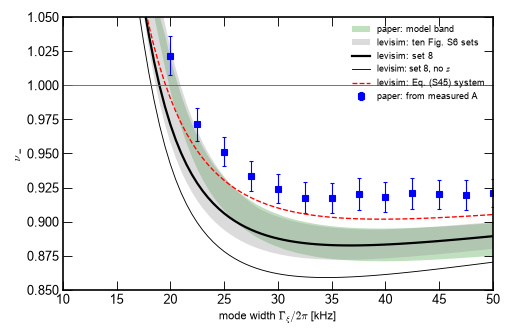

In [ ]:
S6 = DATA['figS6']
psets = [dict(Ωx=110.32 + S6['dΩx_kHz'][i], Ωy=98.16 + S6['dΩy_kHz'][i], gx=S6['gx_kHz'][i], gy=S6['gy_kHz'][i],
              Γx=S6['Γx_kHz'][i], Γy=S6['Γy_kHz'][i], P=S6['P'][i]) for i in range(10)]
datasets = DATA['figS13_S14']['datasets']


def ν_against_width(pset, ΔA, ΔB, widths, z=Z, η=η, κ=κ):
    p = dict(pset, ΔA=ΔA, ΔB=ΔB)
    return np.array([ν_minus(V) for V in V_propagating(deplano_system(p, z=z, κ=κ), p, widths, η=η)])


fig3_set = dict(ΔA=-109.16, ΔB=106.04)
all_sets = np.array([ν_against_width(ps, **fig3_set, widths=widths) for ps in psets])
curve = ν_against_width(psets[7], **fig3_set, widths=widths)
curve_2d = ν_against_width(psets[7], **fig3_set, widths=widths, z=None)
curve_S45 = np.array([ν_minus(V) for V in V_propagating(system_3d, S45, widths)])
η_band = np.array([ν_against_width(psets[7], **fig3_set, widths=widths, η=e, κ=k*kHz)
                   for e in (0.258, 0.283, 0.308) for k in (57, 58, 59)])
i = curve.argmin()
print(f'levisim, set 8 at (−109.16, 106.04) kHz: min ν- = {curve[i]:.4f} at Γξ/2π = {widths[i]:.1f} kHz'
      f'  (η ± 0.025, κ ± 1 kHz: {η_band.min(axis=1).min():.3f}-{η_band.min(axis=1).max():.3f})')
print(f'                                  all ten sets: min ν- between {all_sets.min(axis=1).min():.3f} and {all_sets.min(axis=1).max():.3f}')
print(f'without the axial mode: {curve_2d.min():.4f};  Eq. (S45) system with z: {curve_S45.min():.4f} at {widths[curve_S45.argmin()]:.1f} kHz')
band = DATA['fig3']['model_band']
j = int(np.argmin(np.add(band['ν_lo'], band['ν_hi'])))
print(f'paper (digitised): model band {band["ν_lo"][j]:.3f}-{band["ν_hi"][j]:.3f} at {band["x_kHz"][j]:.1f} kHz; text 0.884 ± 0.011;'
      f' data minimum {min(q["ν"] for q in DATA["fig3"]["points"]):.3f} (text 0.918 ± 0.029)')

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.fill_between(band['x_kHz'], band['ν_lo'], band['ν_hi'], color='g', alpha=0.25, lw=0, label='paper: model band')
pts = DATA['fig3']['points']
ax.errorbar([q['Γξ_kHz'] for q in pts], [q['ν'] for q in pts],
            yerr=[[q['ν'] - q['ν_lo'] for q in pts], [q['ν_hi'] - q['ν'] for q in pts]],
            fmt='s', color='b', ms=5, capsize=2, label='paper: from measured A')
ax.fill_between(widths, all_sets.min(axis=0), all_sets.max(axis=0), color='0.6', alpha=0.35, lw=0, label='levisim: ten Fig. S6 sets')
ax.plot(widths, curve, 'k-', lw=2, label='levisim: set 8')
ax.plot(widths, curve_2d, 'k-', lw=0.8, label='levisim: set 8, no $z$')
ax.plot(widths, curve_S45, 'r--', lw=1.2, label='levisim: Eq. (S45) system')
ax.axhline(1, color='0.4', lw=0.8)
ax.set_xlim(10, 50)
ax.set_ylim(0.85, 1.05)
ax.set_xlabel(r'mode width $\Gamma_\xi/2\pi$ [kHz]')
ax.set_ylabel(r'$\nu_-$')
ax.legend(fontsize=8, frameon=False, loc='upper right')
fig.tight_layout()

## The measured covariance matrices (Figs. S13-S14)

The supplement prints $V$ for every dataset, reconstructed from the measured correlation matrix
$\mathcal{A}$. Their $\nu_-$ is 0.014-0.030 below the blue points of Fig. 4. That is the size of the
axial-mode correction (Sec. IV: "about 0.015 ÷ 0.03"), so the printed matrices do not include it.
Adding the Eq. (S54) contribution recovers the plotted points. The two overlapping markers at 137.41 kHz
are paired here in the order that matches.

In [ ]:
def V_from_print(v):
    a, b13, b14, b23, b24, c33, c44 = v
    return np.array([[a, 0, b13, b14], [0, a, b23, b24], [b13, b23, c33, 0], [b14, b24, 0, c44]])


def in_dataset_order(points, swap_137=False):
    """Fig. 4 markers matched to the datasets by Δ_B; the two markers at 137.41 kHz in either order"""
    out, used = [], set()
    for d in datasets:
        j = min((i for i in range(len(points)) if i not in used), key=lambda i: abs(points[i]['Δ_kHz'] - d['ΔB_kHz']))
        used.add(j)
        out.append(points[j]['ν'])
    if swap_137:
        out[1], out[2] = out[2], out[1]
    return np.array(out)


ν_printed, ν_with_z = [], []
for d in datasets:
    V = V_from_print(d['V'])
    _, xx, pp = eq_S52_S54(dict(psets[3], ΔA=d['ΔA_kHz'], ΔB=d['ΔB_kHz']))   # z correction with set 4
    Vz = V.copy(); Vz[2, 2] += xx; Vz[3, 3] += pp
    ν_printed.append(ν_minus(V)); ν_with_z.append(ν_minus(Vz))
blue = min((in_dataset_order(DATA['fig4']['blue'], s) for s in (False, True)), key=lambda b: np.abs(b - ν_with_z).max())
print(' Δ_B [kHz]  Γξ   ν-(printed V)  ν-(+ z, Eq. S54)  Fig. 4 blue')
for d, a, b, c in zip(datasets, ν_printed, ν_with_z, blue):
    print(f'  {d["ΔB_kHz"]:7.2f}  {d["Γξ_kHz"]:5.1f}   {a:.4f}         {b:.4f}          {c:.4f}')
print(f'printed V below Fig. 4 by {np.min(blue - ν_printed):.3f}-{np.max(blue - ν_printed):.3f};'
      f' with the z correction |difference| ≤ {np.abs(blue - ν_with_z).max():.4f}'
      f' ({np.sum(np.abs(blue - ν_with_z) <= 0.004)} of 10 within 0.004)')

 Δ_B [kHz]  Γξ   ν-(printed V)  ν-(+ z, Eq. S54)  Fig. 4 blue
   145.80   30.0   0.9915         1.0052          1.0052
   137.41   27.5   0.9626         0.9806          0.9803
   137.41   45.0   0.9555         0.9724          0.9692
   129.07   42.5   0.9600         0.9802          0.9731
   116.58   25.0   0.9222         0.9483          0.9455
   106.04   30.0   0.8884         0.9169          0.9185
   106.48   40.0   0.9095         0.9354          0.9324
   106.55   37.5   0.9288         0.9514          0.9513
    95.91   30.0   0.9091         0.9333          0.9321
    96.56   35.0   0.9324         0.9508          0.9481
printed V below Fig. 4 by 0.013-0.030; with the z correction |difference| ≤ 0.0071 (9 of 10 within 0.004)


## Fig. 4: $\nu_-$ against detuning

The paper's bands are "the extremal model predictions generated by the full set of parameters
extracted from all data sets". levisim's bands below are computed the same way: for each of the ten
Fig. S6 sets, at $-\Delta_A = \Delta_B = |\Delta|$, the propagating mode with $\Gamma_\xi$ optimised over
20-50 kHz (green) and the intracavity B mode with the tilt optimised (red), both with the axial mode.

For the individual green points the mapping from the ten parameter sets to the ten datasets is not
given. The best one-to-one assignment is found from the points themselves, so it is a consistency
check, not an independent test. Only set 4 can be placed independently: Eq. (S45) prints its
parameters with the detunings of the 96.56 kHz dataset, and the assignment puts it there. Several sets
give nearly the same $\nu_-$ at a given detuning, so the rest of the assignment is not well determined.
For example, set 5, whose parameters Sec. IV A prints for a 137.4 kHz dataset, is assigned to 129.07 kHz.

best assignment: rms 0.0056; set per dataset (Δ_B order of Figs. S13-S14): [1, 2, 7, 5, 6, 8, 9, 10, 3, 4]
  Δ_B = 145.80 kHz  Γξ = 30.0  set  1: levisim 0.9625  paper (green) 0.9623
  Δ_B = 137.41 kHz  Γξ = 27.5  set  2: levisim 0.9461  paper (green) 0.9439
  Δ_B = 137.41 kHz  Γξ = 45.0  set  7: levisim 0.9485  paper (green) 0.9465
  Δ_B = 129.07 kHz  Γξ = 42.5  set  5: levisim 0.9225  paper (green) 0.9197
  Δ_B = 116.58 kHz  Γξ = 25.0  set  6: levisim 0.9006  paper (green) 0.8935
  Δ_B = 106.04 kHz  Γξ = 30.0  set  8: levisim 0.8876  paper (green) 0.8877
  Δ_B = 106.48 kHz  Γξ = 40.0  set  9: levisim 0.8940  paper (green) 0.9088
  Δ_B = 106.55 kHz  Γξ = 37.5  set 10: levisim 0.8839  paper (green) 0.8844
  Δ_B =  95.91 kHz  Γξ = 30.0  set  3: levisim 0.9029  paper (green) 0.9031
  Δ_B =  96.56 kHz  Γξ = 35.0  set  4: levisim 0.9029  paper (green) 0.9080
levisim green band minimum 0.871 at 105 kHz; red band minimum 0.9756 at 135 kHz
green_band: paper minimum 0.8693; largest |levisim − 

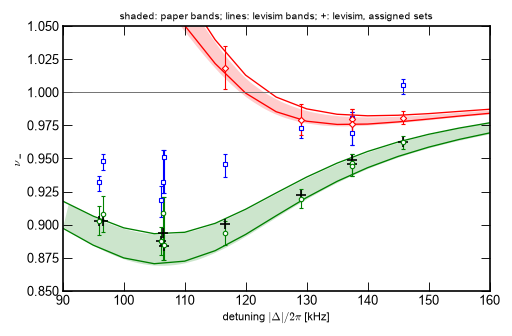

In [ ]:
detunings = np.arange(90, 160.01, 5.0)
opt_widths = np.arange(20, 50.01, 1.0)
green = np.array([[ν_against_width(ps, -D, D, opt_widths).min() for D in detunings] for ps in psets])
red = np.array([[intracavity_ν(dict(ps, ΔA=-D, ΔB=D))[0] for D in detunings] for ps in psets])

model = np.array([[ν_against_width(ps, d['ΔA_kHz'], d['ΔB_kHz'], [d['Γξ_kHz']])[0] for ps in psets] for d in datasets])
best = None
for swap in (False, True):                               # the 137.41 kHz pair can be in either order
    target = in_dataset_order(DATA['fig4']['green'], swap)
    rows, cols = linear_sum_assignment((model - target[:, None])**2)
    rms = np.sqrt(np.mean((model[rows, cols] - target)**2))
    if best is None or rms < best[0]:
        best = (rms, cols, target)
rms, cols, target = best
print(f'best assignment: rms {rms:.4f}; set per dataset (Δ_B order of Figs. S13-S14): {[int(c) + 1 for c in cols]}')
for i, (d, c, t) in enumerate(zip(datasets, cols, target)):
    print(f'  Δ_B = {d["ΔB_kHz"]:6.2f} kHz  Γξ = {d["Γξ_kHz"]:4.1f}  set {c + 1:2d}: levisim {model[i, c]:.4f}  paper (green) {t:.4f}')
print(f'levisim green band minimum {green.min():.3f} at {detunings[green.min(axis=0).argmin()]:.0f} kHz;'
      f' red band minimum {red.min():.4f} at {detunings[red.min(axis=0).argmin()]:.0f} kHz')
for key, values in (('green_band', green), ('red_band', red)):
    b = DATA['fig4'][key]
    inside = (detunings >= min(b['x_kHz'])) & (detunings <= max(b['x_kHz']))
    lo = np.interp(detunings[inside], b['x_kHz'], b['ν_lo'])
    hi = np.interp(detunings[inside], b['x_kHz'], b['ν_hi'])
    unclipped = hi < 1.049                              # the paper's axes end at 1.05
    d_lo = np.abs(values.min(axis=0)[inside] - lo)
    d_hi = np.where(unclipped, np.abs(values.max(axis=0)[inside] - hi), 0)
    print(f'{key}: paper minimum {min(b["ν_lo"]):.4f}; largest |levisim − paper| over'
          f' {detunings[inside][0]:.0f}-{detunings[inside][-1]:.0f} kHz: lower edge {d_lo.max():.4f}'
          f' (at {detunings[inside][d_lo.argmax()]:.0f} kHz), upper edge {d_hi.max():.4f} (at {detunings[inside][d_hi.argmax()]:.0f} kHz);'
          f' upper edge within 0.005 at {np.sum(unclipped & (d_hi < 0.005))} of {unclipped.sum()} detunings')

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for key, colour in (('green_band', 'g'), ('red_band', 'r')):
    b = DATA['fig4'][key]
    ax.fill_between(b['x_kHz'], b['ν_lo'], b['ν_hi'], color=colour, alpha=0.2, lw=0)
for values, colour in ((green, 'g'), (red, 'r')):
    ax.plot(detunings, values.min(axis=0), '-', color=colour, lw=1.2)
    ax.plot(detunings, values.max(axis=0), '-', color=colour, lw=1.2)
for key, colour, marker in (('blue', 'b', 's'), ('green', 'g', 'o'), ('red', 'r', 'D')):
    q = DATA['fig4'][key]
    ax.errorbar([v['Δ_kHz'] for v in q], [v['ν'] for v in q],
                yerr=[[v['ν'] - v['ν_lo'] for v in q], [v['ν_hi'] - v['ν'] for v in q]],
                fmt=marker, color=colour, ms=4, capsize=2, mfc='white')
ax.plot([d['ΔB_kHz'] for d in datasets], [model[i, c] for i, c in enumerate(cols)], 'k+', ms=9, mew=1.5)
ax.axhline(1, color='0.4', lw=0.8)
ax.set_xlim(90, 160)
ax.set_ylim(0.85, 1.05)
ax.set_xlabel(r'detuning $|\Delta|/2\pi$ [kHz]')
ax.set_ylabel(r'$\nu_-$')
ax.set_title('shaded: paper bands; lines: levisim bands; +: levisim, assigned sets', fontsize=9)
fig.tight_layout()

## Summary

All numbers below are printed by the cells above.

**Agreement.**

- The bright-mode transformation of Eqs. (S6-S10) with the Eq. (S45) parameters gives
  $\Omega_b/2\pi$ = 106.01 kHz, $g_A/2\pi$ = 11.69 kHz and $g_B/2\pi$ = 6.30 kHz (Fig. 2 caption: 106, 11.7, 6.3).
- With the paper's momentum-only diffusion, levisim's two-cavity-mode model reproduces every printed
  digit of the worked covariance matrix Eq. (S45) at $\Gamma_\xi/2\pi$ = 40 kHz. With levisim's own
  bath, only $\langle x_b p_b\rangle$ differs (−0.03 instead of 0, which is the bath's quadrature
  diffusion); $\nu_-$ changes by at most $1.1 \times 10^{-3}$ over 10-50 kHz.
- Axial mode: Eq. (S52) gives $\gamma_\mathrm{opt}/2\pi$ = 14.6 Hz (Fig. S9: "14.5", so the unit is Hz),
  and the exact 3D model adds 0.222 to $\langle x_b^2\rangle$ and 0.0080 to $\langle p_b^2\rangle$ (Eq. S54:
  0.237 and 0.0078; text: 0.22 and 0.007). The optical and cross entries change by $2 \times 10^{-4}$,
  so the filter does remove $z$ from the propagating mode, as stated.
- Intracavity entanglement (Sec. IV A): optimal tilt 1.99° (paper 2.0°), $\nu_-$ = 0.977 (paper 0.976 ±
  0.007); the 2D bright mode is not entangled ($\nu_-$ = 1.88). The printed 10 × 10 matrix is
  reproduced with a median deviation of −2 % (55 of the 58 entries larger than 1 within 3 %).
- Fig. 3: for the 110 kHz dataset, levisim's minimum is 0.883 at $\Gamma_\xi/2\pi$ = 36.5 kHz with the
  assigned set (0.874-0.892 for η ± 0.025, κ ± 1 kHz), and between 0.872 and 0.894 for all ten sets.
  The paper's model band at its minimum is 0.871-0.895 (text 0.884 ± 0.011) at 39.5 kHz. The shape
  against $\Gamma_\xi$, including the crossing of $\nu_- = 1$ near 20 kHz, follows the paper's band.
  Without the axial mode the minimum would be 0.859.
- The measured matrices of Figs. S13-S14 give $\nu_-$ 0.013-0.030 below the Fig. 4 data points. Adding
  the Eq. (S54) axial-mode correction recovers the points to within 0.004 for 9 of the 10 datasets
  (0.007 for the tenth).
- Fig. 4: levisim's bands, computed from the ten Fig. S6 sets as the paper describes, match the paper's.
  The minima are 0.871 at 105 kHz (paper 0.869 at 106 kHz) for the propagating mode and 0.9756 at
  135 kHz (paper 0.9745 at 136 kHz) for the intracavity mode. The lower edges agree to 0.0013 and
  0.0044, and the upper edges to 0.005 at every detuning except the green band's end point at 90 kHz.
- The best assignment of the ten sets to the ten datasets reproduces the green points with rms 0.006.
  It puts set 4 (the Fig. 2 / S5 fit) on the 96.56 kHz dataset of Eq. (S45). The largest misfits are
  0.894 against 0.909 at 106.48 kHz and 0.901 against 0.894 at 116.58 kHz.

**What is not reproduced, and why.**

- The measured points themselves (Figs. 3 and 4, blue) come from the experimental correlation
  matrix $\mathcal{A}$. levisim has no access to it and only the model is computed. The paper attributes
  the gap (data above model by about 0.03) to slow parameter fluctuations during each 20 s
  acquisition, which the stationary model cannot describe.
- The individual green points of Fig. 4 need the per-dataset parameters, but the paper does not say
  which Fig. S6 set belongs to which dataset. The assignment used here is fitted, so it is only a
  consistency check, and it is not unique: set 5 matches the parameters printed for a 137.4 kHz dataset
  in Sec. IV A, but it is assigned to 129.07 kHz.
- The spectral matrices of Figs. 2a, S7, S8 and S10 and the finite-sample bias of Fig. S12 are not
  reproduced; they are properties of the measured data.

**Inconsistencies in the paper's stated values** (neutral, from its own numbers):

- Sec. IV defines the flat window as $\xi(\omega) = 1/\sqrt{2\pi\Gamma_\xi}$. With the paper's own
  convention $a_\xi = \int \xi(\omega) a_\mathrm{out}(\omega)\, d\omega/2\pi$, the normalisation $\int|\xi|^2 d\omega/2\pi = 1$
  (needed for $[a_\xi, a_\xi^\dagger] = 1$) requires $\xi = \sqrt{2\pi/\Gamma_\xi}$. The printed matrices (vacuum
  level 1, Eq. S45 reproduced) are consistent with the normalised mode, so this reads as a typo.
- The printed $V^{bd}$ of Sec. IV A is not symmetric in three entries (listed above).
- The optimal width is "around 35 kHz" in the main text and 40 kHz in Sec. IV (both are near the
  flat minimum: $\nu_-$ changes by less than 0.003 between 35 and 45 kHz).
- The Fig. S9 caption gives $\gamma_\mathrm{opt}/2\pi$ = 14.5 without a unit; Eq. (S52) shows it is Hz.
- The printed covariance matrices of Figs. S13-S14 do not include the axial-mode correction, while
  the $\nu_-$ values plotted from them in Fig. 4 do, which the captions do not say.

In [ ]:
print(f'notebook runtime: {time.time() - T_START:.1f} s')

notebook runtime: 6.1 s
